# Link prediction: why the KGs differ (no training)

Two analyses of runs that already exist. They need the outputs of `link_prediction_{rgcn,graphsage}.ipynb`, the
LP ablation and the R-GCN depth check (`link_prediction_rgcn_depth.ipynb`).

1. **Hop table.** For each target, the number of message-passing hops from the query head (or a candidate) to the
   literals that identify the answer, computed from the three schemas (`evidence_hops`). Beside it, each main run's
   depth and test MRR. Where the evidence is out of reach at that depth, the hypothesis predicts a low score.
2. **Position by session evidence.** The hop table says that a model at K = 3 reads a session's rank in Ad-hoc
   (3 hops) but not behind the rank reification (4 hops). If that is the mechanism, the advantage of a direct rank
   must sit entirely in the test entries that have a session with a position (qualifying, sprint or practice).
   Entries without one (mostly before 1994) have no session rank to read in any graph. The saved best-val
   checkpoints are re-scored per query on the test races (`query_ranks_on`).
   Prediction (stated before the analysis): with a session, direct rank ≈ 0.45 vs reified ≈ 0.28; without one,
   the two are about equal.

In [5]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from f1_node_data import ABLATION_VARIANTS, ablation_schema, load_population
from f1_population import SCHEMA_FILES, read_schema
from link_prediction.link_prediction_tools import (
    EVIDENCE_CHAINS, TARGETS, LinkPredictor, build_lp_data, evidence_hops, query_ranks_on, race_split,
    ranking_metrics, session_position_entries,
)
from node_prediction.gnn_tools import cleanup
from node_prediction.models import RGCNModel

LP_DIR = ROOT / "outputs" / "f1" / "link_prediction"
ABLATION_DIR = LP_DIR / "ablation" / "rgcn"
DEPTH_DIR = LP_DIR / "depth" / "rgcn"
OUT_DIR = LP_DIR / "analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)
KGS = ["adhoc", "hybrid_sulo", "pure_sulo"]
NAMES = {"adhoc": "Ad-hoc", "hybrid_sulo": "Hybrid", "pure_sulo": "Pure"}

## 1. Hop table

Hops from the query head (or a candidate) to the evidence, per KG, then each main run's depth and test MRR per
target (mean over `FINAL_SEEDS`).

In [6]:
schemas = {kg: read_schema(str(ROOT / path)) for kg, path in SCHEMA_FILES.items()}
hops = pd.DataFrame({NAMES[kg]: {name: evidence_hops(schemas[kg], chain) for name, chain in EVIDENCE_CHAINS.items()}
                     for kg in KGS})
hops.to_csv(OUT_DIR / "hop_table.csv")
hops

,Ad-hoc,Hybrid,Pure
"LP team: the driver's literals, from the entry",2,2,4
"LP team: the team's literals, from a candidate",1,1,2
"LP position: a session's rank, from the entry",3,4,4
"LP position: the rank, from a candidate",1,2,2
"LP circuit: the race's literals, from the race",1,1,2
"LP circuit: the circuit's literals, from a candidate",1,1,2
NP: the entry's own grid rank,2,3,3


In [7]:
main = {}
for enc in ("rgcn", "graphsage"):
    for kg in KGS:
        rows = pd.read_csv(LP_DIR / enc / f"{kg}_sequential_tuning_results.csv").query("phase == '4_Final_Test_Evaluation'")
        main[(enc, NAMES[kg])] = {"layers K": int(rows["layers"].iloc[0]),
                                  **{f"{t} test MRR": rows[f"test_{t}_mrr"].mean() for t in TARGETS}}
main = pd.DataFrame(main).T
main.round(3).to_csv(OUT_DIR / "main_runs_by_depth.csv")
main.round(3)

layers K  team test MRR  position test MRR  circuit test MRR
rgcn      Ad-hoc       3.0          0.727              0.405             0.934
          Hybrid       3.0          0.721              0.277             0.934
          Pure         2.0          0.267              0.235             0.931
graphsage Ad-hoc       3.0          0.397              0.258             0.555
          Hybrid       3.0          0.329              0.251             0.338
          Pure         3.0          0.212              0.216             0.286

## 2. Position by session evidence

The R-GCN checkpoints scored here: the ablation's two controls and two `rank_reification` variants (K = 3), and
the depth check's runs (K = 3 for Pure, K = 4 for all three KGs). Each is rebuilt from its CSV row's configuration;
`FEATURE_DIM` must equal the training notebooks' value, otherwise the checkpoint does not load.

In [8]:
# Must equal the training notebooks' constant (link_prediction_rgcn*.ipynb); the state dict would not load otherwise.
FEATURE_DIM = 256
DROPOUT = 0.2      # inactive in eval mode; kept equal to training for clarity

entities, assertions = load_population(ROOT / "data" / "f1")
split = race_split(entities, seed=42)
graphs = {name: build_lp_data(ABLATION_VARIANTS[name][0], entities, assertions, split, ablation_schema(name, schemas))
          for name in ["adhoc", "hybrid_sulo", "hybrid_minus_rank_reification", "adhoc_plus_rank_reification"]}
graphs["pure_sulo"] = build_lp_data("pure_sulo", entities, assertions, split, schemas["pure_sulo"])

# label -> (graph, results CSV, variant in that CSV, checkpoint directory)
RUNS = {
    "Ad-hoc, K = 3": ("adhoc", ABLATION_DIR / "ablation_results.csv", "adhoc", ABLATION_DIR / "checkpoints"),
    "Hybrid, K = 3": ("hybrid_sulo", ABLATION_DIR / "ablation_results.csv", "hybrid_sulo", ABLATION_DIR / "checkpoints"),
    "Hybrid − rank reification, K = 3": ("hybrid_minus_rank_reification", ABLATION_DIR / "ablation_results.csv",
                                         "hybrid_minus_rank_reification", ABLATION_DIR / "checkpoints"),
    "Ad-hoc + rank reification, K = 3": ("adhoc_plus_rank_reification", ABLATION_DIR / "ablation_results.csv",
                                         "adhoc_plus_rank_reification", ABLATION_DIR / "checkpoints"),
    "Pure, K = 3": ("pure_sulo", DEPTH_DIR / "K3.csv", "pure_sulo", DEPTH_DIR / "checkpoints" / "K3"),
    **{f"{NAMES[kg]}, K = 4": (kg, DEPTH_DIR / "K4.csv", kg, DEPTH_DIR / "checkpoints" / "K4") for kg in KGS},
}

with_session = session_position_entries(assertions)
with_qualifying = session_position_entries(assertions, "Qualifying")


def position_ranks(graph, row, checkpoint):
    """Test Position (head IRI, rank) of one saved best-val checkpoint."""
    d = graphs[graph]
    hidden = [int(row["hidden_dim"])] * (int(row["layers"]) - 1)
    dim = hidden[-1] if hidden else FEATURE_DIM
    bases = None if pd.isna(row["num_bases"]) else int(row["num_bases"])
    model = LinkPredictor(RGCNModel(num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden,
                                    num_relations=d.num_relations, num_bases=bases, out_channels=dim,
                                    dropout=DROPOUT), len(TARGETS), dim)
    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=False)["model_state_dict"])
    head, rank = query_ranks_on(model, d, "test")["position"]
    iri_of = {i: iri.strip("<>") for iri, i in d.node_ids.items()}
    del model
    cleanup()
    return [iri_of[h] for h in head.tolist()], rank


per_seed = []
for label, (graph, csv, variant, ckpt_dir) in RUNS.items():
    rows = pd.read_csv(csv).query("variant == @variant and status == 'ok'")
    assert not rows.empty, f"{label}: no rows in {csv}"
    for _, row in rows.iterrows():
        heads, rank = position_ranks(graph, row, ckpt_dir / f"{variant}_seed{int(row['seed'])}.pt")
        has = torch.tensor([h in with_session for h in heads])
        per_seed.append({"run": label, "seed": int(row["seed"]),
                         "all": ranking_metrics(rank)["mrr"], "csv test_position_mrr": row["test_position_mrr"],
                         "with a session position": ranking_metrics(rank[has])["mrr"],
                         "without": ranking_metrics(rank[~has])["mrr"],
                         "n with": int(has.sum()), "n without": int((~has).sum()),
                         "n with qualifying": sum(h in with_qualifying for h in heads)})
per_seed = pd.DataFrame(per_seed)
# Re-scoring a checkpoint must give the test MRR its run logged (GPU scatter noise aside).
assert np.allclose(per_seed["all"], per_seed["csv test_position_mrr"], atol=2e-3), "re-scored MRR differs from the CSV"
per_seed.to_csv(OUT_DIR / "position_by_session_per_seed.csv", index=False)

groups = ["all", "with a session position", "without"]
by_session = per_seed.groupby("run", sort=False)[groups].agg(["mean", "std"])
by_session[("n", "with")] = per_seed.groupby("run", sort=False)["n with"].first()
by_session[("n", "without")] = per_seed.groupby("run", sort=False)["n without"].first()
by_session.round(4).to_csv(OUT_DIR / "position_by_session.csv")
by_session.round(4)

all         with a session position  \
                                    mean     std                    mean   
run                                                                        
Ad-hoc, K = 3                     0.4090  0.0761                  0.6158   
Hybrid, K = 3                     0.2738  0.0028                  0.3015   
Hybrid − rank reification, K = 3  0.4384  0.0174                  0.6829   
Ad-hoc + rank reification, K = 3  0.2744  0.0040                  0.3070   
Pure, K = 3                       0.2410  0.0057                  0.2623   
Ad-hoc, K = 4                     0.4524  0.0168                  0.7070   
Hybrid, K = 4                     0.3428  0.0896                  0.4560   
Pure, K = 4                       0.2586  0.0083                  0.2810   

                                         without             n          
                                     std    mean     std  with without  
run                                                                     
Ad-hoc, K = 3                     0.1731  0.2513  0.0034  1114    1461  
Hybrid, K = 3                     0.0050  0.2528  0.0025  1114    1461  
Hybrid − rank reification, K = 3  0.0384  0.2520  0.0044  1114    1461  
Ad-hoc + rank reification, K = 3  0.0070  0.2495  0.0034  1114    1461  
Pure, K = 3                       0.0096  0.2248  0.0050  1114    1461  
Ad-hoc, K = 4                     0.0422  0.2582  0.0063  1114    1461  
Hybrid, K = 4                     0.2076  0.2565  0.0060  1114    1461  
Pure, K = 4                       0.0125  0.2416  0.0060  1114    1461

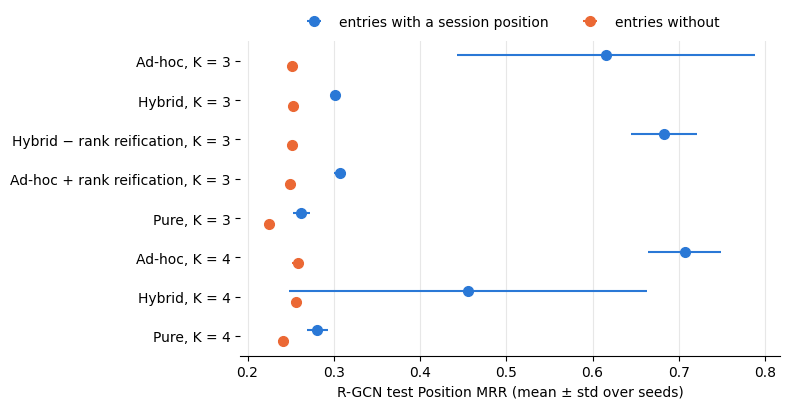

In [9]:
# Validated default categorical palette (dataviz skill): slot 1 = with a session position, slot 2 = without.
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(by_session))
for offset, (group, color) in zip((-0.14, 0.14), [("with a session position", "#2a78d6"), ("without", "#eb6834")]):
    ax.errorbar(by_session[(group, "mean")], y + offset, xerr=by_session[(group, "std")], fmt="o", markersize=7,
                color=color, elinewidth=1.5, capsize=0, label=f"entries {group}")
ax.set_yticks(y, by_session.index)
ax.invert_yaxis()
ax.set_xlabel("R-GCN test Position MRR (mean ± std over seeds)")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "position_by_session.png", dpi=200)
plt.show()